# Clasificación de Alzheimer con YOLOv5 (repositorio original `ultralytics/yolov5`)
Mismo flujo que el notebook de YOLO26/11/8: carga de datos desde Drive, split 70/10/20, entrenamiento, métricas, matriz de confusión y Grad-CAM.
> YOLOv5 clasificación **no** se maneja con el paquete `ultralytics`, sino con el repo original (`classify/train.py`).

In [ ]:
!nvidia-smi

Fri Oct  9 23:02:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 1. Instalar YOLOv5 (repo original) y dependencias auxiliares
import os, sys, torch

YOLOV5_DIR = "/content/yolov5"
if not os.path.exists(YOLOV5_DIR):
    !git clone -q https://github.com/ultralytics/yolov5 {YOLOV5_DIR}
!pip install -q -r {YOLOV5_DIR}/requirements.txt scikit-learn matplotlib seaborn grad-cam ttach

# Evita el error de torch.load con torch >= 2.6 al cargar checkpoints de YOLOv5
os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"

assert torch.cuda.is_available(), "❌ No hay GPU activa. Cambia el tipo de entorno de ejecución a GPU (T4)."
print("✅ GPU detectada:", torch.cuda.get_device_name(0))
print("Torch versión:", torch.__version__, "| CUDA:", torch.version.cuda)

import pytorch_grad_cam
print("✅ pytorch_grad_cam importado con éxito.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 28.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 7.4 MB/s eta 0:00:00
✅ GPU detectada: Tesla T4
Torch versión: 2.11.0+cu130 | CUDA: 13.0
✅ pytorch_grad_cam importado con éxito.


In [ ]:
import os, shutil, zipfile

# >>> RUTA DE TU ZIP EN DRIVE <<<
ZIP_DRIVE_PATH = "/content/drive/MyDrive/tallermovil/Dataset/data_Alzheimer.zip"

ZIP_LOCAL_PATH = "/content/data_Alzheimer.zip"   # copia local temporal
DATA_ROOT      = "/content/data_Alzheimer"       # carpeta descomprimida

if os.path.exists(DATA_ROOT):
    print("ℹ️ El dataset ya está descomprimido en", DATA_ROOT, "(se omite este paso).")
else:
    print("Copiando ZIP desde Drive al disco local...")
    shutil.copy(ZIP_DRIVE_PATH, ZIP_LOCAL_PATH)

    print("Descomprimiendo...")
    with zipfile.ZipFile(ZIP_LOCAL_PATH) as z:
        nombres_zip = [n for n in z.namelist() if n.strip("/") and not n.startswith("__MACOSX")]
        trae_raiz = all(n.split("/")[0] == "data_Alzheimer" for n in nombres_zip)
        destino = "/content" if trae_raiz else DATA_ROOT
        z.extractall(destino)

# Verificación de la estructura y conteo de imágenes por carpeta
EXT = {".jpg", ".jpeg", ".png", ".bmp"}
for origen in ["OriginalDataset", "AugmentedAlzheimerDataset"]:
    print(f"\n📁 {origen}")
    base = os.path.join(DATA_ROOT, origen)
    if os.path.exists(base):
        for clase in sorted(os.listdir(base)):
            ruta = os.path.join(base, clase)
            if os.path.isdir(ruta):
                n = sum(1 for f in os.listdir(ruta) if os.path.splitext(f)[1].lower() in EXT)
                print(f"   {clase:<20} {n:>6} imágenes")

Copiando ZIP desde Drive al disco local...
Descomprimiendo...

📁 OriginalDataset
   MildDemented            896 imágenes
   ModerateDemented         64 imágenes
   NonDemented            3200 imágenes
   VeryMildDemented       2240 imágenes

📁 AugmentedAlzheimerDataset
   MildDemented           8960 imágenes
   ModerateDemented       6464 imágenes
   NonDemented            9600 imágenes
   VeryMildDemented       8960 imágenes


In [ ]:
from pathlib import Path

# ============================ PARÁMETROS DEL EXPERIMENTO ============================
YOLO_VERSION   = 'yolov5n-cls.pt'        # 'yolov5n-cls.pt' | 'yolov5s-cls.pt' | 'yolov5m-cls.pt' | 'yolov5l-cls.pt' | 'yolov5x-cls.pt'
DATASET_SOURCE = 'AugmentedAlzheimerDataset'       # 'OriginalDataset' | 'AugmentedAlzheimerDataset'

TRAIN_RATIO = 0.70
VAL_RATIO   = 0.10
TEST_RATIO  = 0.20

EPOCHS     = 20
BATCH_SIZE = 16          # 16 o 32 (si te quedas sin memoria GPU, bájalo a 16)
IMAGE_SIZE = 224         # 224 píxeles (resolución estándar rápida)
SEED       = 42
WORKERS    = 2

EVAL_BATCH_SIZE = BATCH_SIZE

# >>> RUTA DE GUARDADO EN TU DRIVE <<<
DRIVE_PROJECT_DIR = "/content/drive/MyDrive/tallermovil/runs"
# ====================================================================================

RUN_NAME = f"{YOLO_VERSION.replace('.pt', '')}_{DATASET_SOURCE}_{IMAGE_SIZE}px_{EPOCHS}ep"

assert DATASET_SOURCE in ('OriginalDataset', 'AugmentedAlzheimerDataset'), "DATASET_SOURCE inválido"
assert abs((TRAIN_RATIO + VAL_RATIO + TEST_RATIO) - 1.0) < 1e-6, "Los ratios deben sumar 1.0"
os.makedirs(DRIVE_PROJECT_DIR, exist_ok=True)

print("Modelo      :", YOLO_VERSION)
print("Dataset     :", DATASET_SOURCE)
print(f"Split       : train={TRAIN_RATIO:.0%} | val={VAL_RATIO:.0%} | test={TEST_RATIO:.0%}")
print(f"Épocas/Batch: {EPOCHS} / {BATCH_SIZE}  | Resolución: {IMAGE_SIZE}px")
print("Run name    :", RUN_NAME)

Modelo      : yolov5n-cls.pt
Dataset     : AugmentedAlzheimerDataset
Split       : train=70% | val=10% | test=20%
Épocas/Batch: 20 / 16  | Resolución: 224px
Run name    : yolov5n-cls_AugmentedAlzheimerDataset_224px_20ep


In [ ]:
import random

SRC_DIR = Path(DATA_ROOT) / DATASET_SOURCE
DST_DIR = Path("/content/dataset_yolo_prepared")

if DST_DIR.exists():
    shutil.rmtree(DST_DIR)

clases = sorted(d.name for d in SRC_DIR.iterdir() if d.is_dir())
print("Clases detectadas:", clases)

rng = random.Random(SEED)
conteo = {}

for clase in clases:
    imgs = sorted(p for p in (SRC_DIR / clase).iterdir() if p.suffix.lower() in EXT)
    rng.shuffle(imgs)

    n = len(imgs)
    n_train = int(round(n * TRAIN_RATIO))
    n_val   = int(round(n * VAL_RATIO))

    particiones = {
        "train": imgs[:n_train],
        "val":   imgs[n_train:n_train + n_val],
        "test":  imgs[n_train + n_val:],
    }

    for split, lista in particiones.items():
        destino = DST_DIR / split / clase
        destino.mkdir(parents=True, exist_ok=True)
        for p in lista:
            shutil.copy2(p, destino / p.name)
        conteo[(clase, split)] = len(lista)

# Resumen en pantalla
print(f"\n{'Clase':<20}{'train':>8}{'val':>8}{'test':>8}{'total':>8}")
print("-" * 52)
tot = {"train": 0, "val": 0, "test": 0}
for clase in clases:
    fila = [conteo[(clase, s)] for s in ("train", "val", "test")]
    for s, v in zip(tot, fila):
        tot[s] += v
    print(f"{clase:<20}{fila[0]:>8}{fila[1]:>8}{fila[2]:>8}{sum(fila):>8}")
print("-" * 52)
print(f"{'TOTAL':<20}{tot['train']:>8}{tot['val']:>8}{tot['test']:>8}{sum(tot.values()):>8}")

Clases detectadas: ['MildDemented', 'ModerateDemented', 'NonDemented', 'VeryMildDemented']

Clase                  train     val    test   total
----------------------------------------------------
MildDemented            6272     896    1792    8960
ModerateDemented        4525     646    1293    6464
NonDemented             6720     960    1920    9600
VeryMildDemented        6272     896    1792    8960
----------------------------------------------------
TOTAL                  23789    3398    6797   33984


In [ ]:
# Entrenamiento con el script de clasificación del repo original de YOLOv5
os.chdir(YOLOV5_DIR)
sys.path.insert(0, YOLOV5_DIR)

cmd = (f"python classify/train.py --model {YOLO_VERSION} --data /content/dataset_yolo_prepared "
       f"--epochs {EPOCHS} --batch-size {BATCH_SIZE} --imgsz {IMAGE_SIZE} "
       f"--project {DRIVE_PROJECT_DIR} --name {RUN_NAME} --seed {SEED} "
       f"--workers {WORKERS} --device 0 --exist-ok")
print(cmd, "\n")
!{cmd}

SAVE_DIR = Path(DRIVE_PROJECT_DIR) / RUN_NAME
print("\n✅ Entrenamiento finalizado. Resultados guardados en:", SAVE_DIR)
print("Mejor modelo:", SAVE_DIR / "weights" / "best.pt")

python classify/train.py --model yolov5n-cls.pt --data /content/dataset_yolo_prepared --epochs 20 --batch-size 16 --imgsz 224 --project /content/drive/MyDrive/tallermovil/runs --name yolov5n-cls_AugmentedAlzheimerDataset_224px_20ep --seed 42 --workers 2 --device 0 --exist-ok 

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791587169.595940    3436 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 secon

    epoch  train/loss  test/loss  metrics/accuracy_top1  \
15     15     0.57747    0.46347                0.94807   
16     16     0.56342    0.45843                0.95145   
17     17     0.54642    0.45250                0.95469   
18     18     0.52959    0.44791                0.95748   
19     19     0.52120    0.44315                0.95881   

    metrics/accuracy_top5      lr/0  
15                      1  0.000208  
16                      1  0.000159  
17                      1  0.000109  
18                      1  0.000060  
19                      1  0.000010  


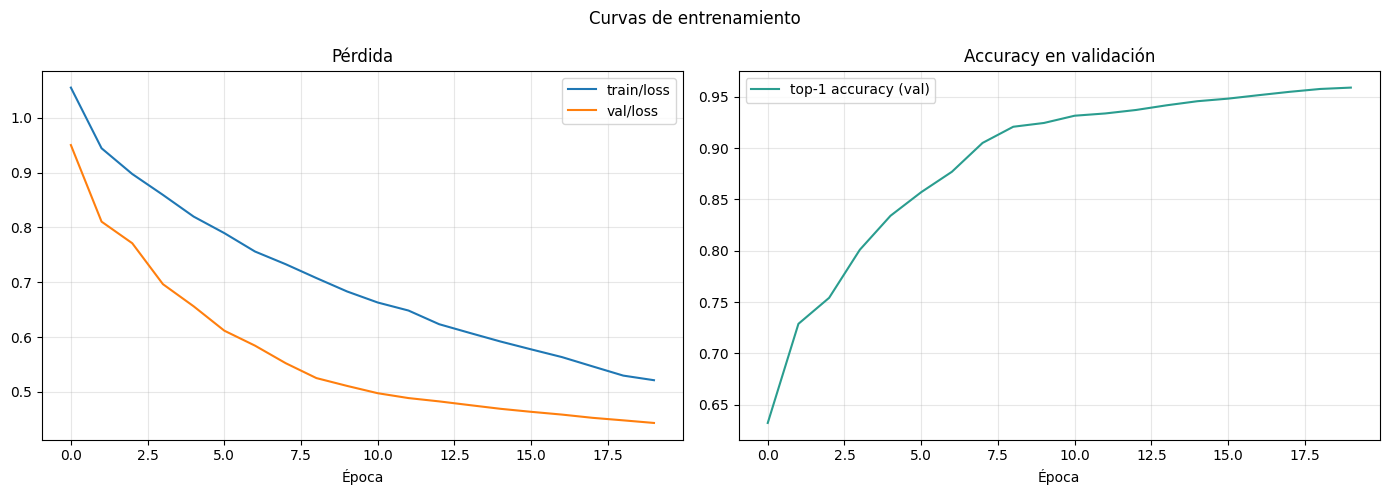

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(SAVE_DIR / "results.csv")
df.columns = [c.strip() for c in df.columns]
print(df.tail())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(df["epoch"], df["train/loss"], label="train/loss")
axes[0].plot(df["epoch"], df["val/loss"], label="val/loss")
axes[0].set_title("Pérdida"); axes[0].set_xlabel("Época"); axes[0].legend(); axes[0].grid(alpha=.3)

axes[1].plot(df["epoch"], df["metrics/accuracy_top1"], label="top-1 accuracy (val)", color="#2a9d8f")
axes[1].set_title("Accuracy en validación"); axes[1].set_xlabel("Época"); axes[1].legend(); axes[1].grid(alpha=.3)

fig.suptitle("Curvas de entrenamiento"); plt.tight_layout(); plt.show()

In [ ]:
import gc
import numpy as np
from PIL import Image
from torchvision import transforms as T

DEVICE = "cuda"
RUTA_MODELO = str(SAVE_DIR / "weights" / "best.pt")

# Cargar el checkpoint del repo original (best.pt guarda el modelo completo)
ckpt = torch.load(RUTA_MODELO, map_location="cpu", weights_only=False)
best_model = (ckpt.get("ema") or ckpt["model"]).float().to(DEVICE).eval()
del ckpt

# Importante para Grad-CAM: desactivar activaciones in-place (YOLOv5 las activa por defecto)
for m in best_model.modules():
    if hasattr(m, "inplace"):
        m.inplace = False

nombres = best_model.names
if isinstance(nombres, (list, tuple)):
    nombres = {i: n for i, n in enumerate(nombres)}
etiquetas = [nombres[i] for i in sorted(nombres)]
assert etiquetas == clases, f"Orden de clases distinto: modelo={etiquetas} vs carpetas={clases}"

# Mismo preprocesado que usa YOLOv5-cls (resize + center crop + normalización ImageNet)
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
preprocesar = T.Compose([T.Resize(IMAGE_SIZE), T.CenterCrop(IMAGE_SIZE), T.ToTensor(), T.Normalize(MEAN, STD)])

def a_probs(out):
    out = out[0] if isinstance(out, (tuple, list)) else out
    if out.min() >= 0 and torch.allclose(out.sum(1), torch.ones(out.shape[0], device=out.device), atol=1e-3):
        return out                      # ya son probabilidades
    return torch.softmax(out, dim=1)    # eran logits

# ===== Evaluación sobre TEST =====
test_dir = Path("/content/dataset_yolo_prepared/test")
rutas, y_true = [], []
for idx in sorted(nombres):
    for p in sorted((test_dir / nombres[idx]).iterdir()):
        rutas.append(str(p)); y_true.append(idx)

y_pred = []
with torch.no_grad():
    for i in range(0, len(rutas), EVAL_BATCH_SIZE):
        lote = torch.stack([preprocesar(Image.open(r).convert("RGB")) for r in rutas[i:i + EVAL_BATCH_SIZE]]).to(DEVICE)
        probs_lote = a_probs(best_model(lote))
        y_pred.extend(probs_lote.argmax(1).cpu().tolist())

gc.collect(); torch.cuda.empty_cache()
top1 = float(np.mean(np.array(y_true) == np.array(y_pred)))
print(f"✅ Predicciones completadas sobre {len(y_pred)} imágenes de test.")
print(f"\n🎯 Top-1 accuracy en TEST: {top1:.4f}  ({top1 * 100:.2f}%)")

✅ Predicciones completadas sobre 6797 imágenes de test.

🎯 Top-1 accuracy en TEST: 0.9581  (95.81%)


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_true, y_pred, target_names=etiquetas, digits=4))

                  precision    recall  f1-score   support

    MildDemented     0.9598    0.9994    0.9792      1792
ModerateDemented     1.0000    0.9992    0.9996      1293
     NonDemented     0.9646    0.9073    0.9351      1920
VeryMildDemented     0.9203    0.9414    0.9308      1792

        accuracy                         0.9581      6797
       macro avg     0.9612    0.9618    0.9612      6797
    weighted avg     0.9584    0.9581    0.9578      6797



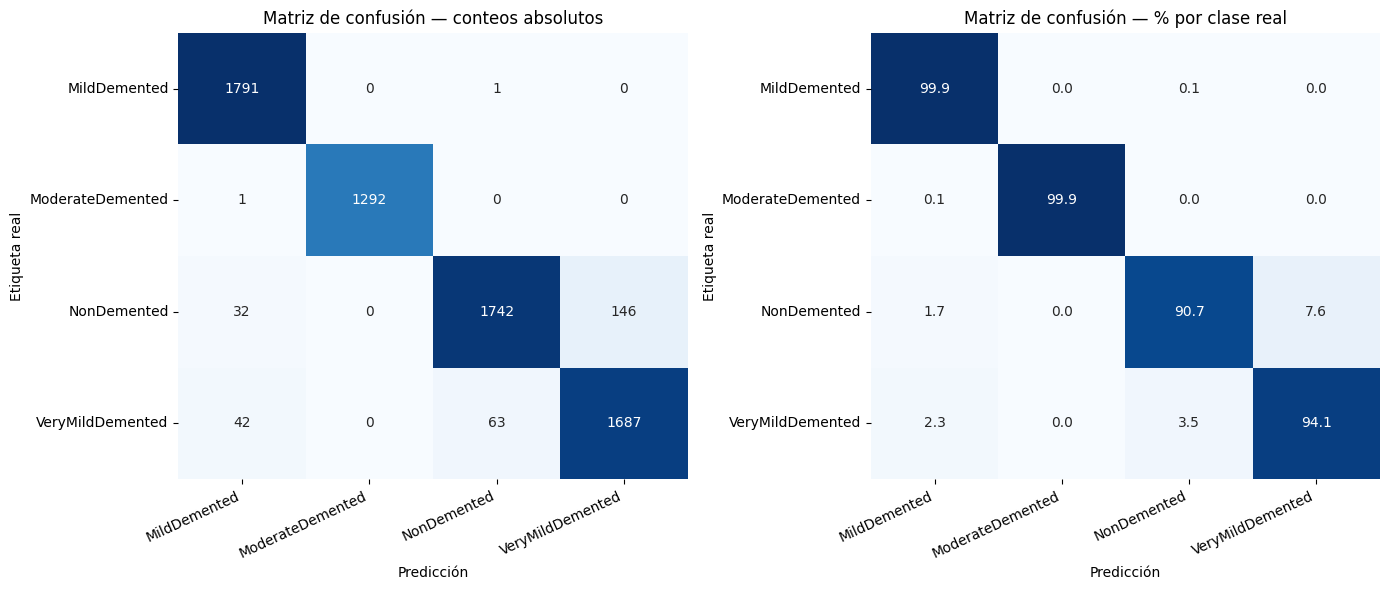

In [ ]:
import seaborn as sns

cm = confusion_matrix(y_true, y_pred, labels=sorted(nombres))
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=etiquetas, yticklabels=etiquetas, ax=axes[0])
axes[0].set_title("Matriz de confusión — conteos absolutos")
axes[0].set_xlabel("Predicción"); axes[0].set_ylabel("Etiqueta real")

sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Blues", cbar=False,
            xticklabels=etiquetas, yticklabels=etiquetas, ax=axes[1])
axes[1].set_title("Matriz de confusión — % por clase real")
axes[1].set_xlabel("Predicción"); axes[1].set_ylabel("Etiqueta real")

for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=25, ha="right")

plt.tight_layout(); plt.show()

In [ ]:
# Preparación del modelo para Grad-CAM
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

torch_model = best_model
for param in torch_model.parameters():
    param.requires_grad = True

# Envoltorio para asegurar que el modelo devuelva un Tensor puro
class YOLOClsWrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        out = self.model(x)
        return out[0] if isinstance(out, (tuple, list)) else out

model_wrapped = YOLOClsWrapper(torch_model)

# Última capa del backbone (justo antes de la cabeza Classify)
CAPA_OBJETIVO = [torch_model.model[-2]]
print("✅ Gradientes activados y Wrapper para Grad-CAM configurado correctamente.")

✅ Gradientes activados y Wrapper para Grad-CAM configurado correctamente.


In [ ]:
def diagnosticar_con_gradcam(ruta_img):
    img_pil = Image.open(ruta_img).convert("RGB")
    tensor = preprocesar(img_pil).unsqueeze(0).to(DEVICE)

    # 1. Probabilidades de predicción
    with torch.no_grad():
        probs = a_probs(model_wrapped(tensor))[0].cpu().numpy()

    top1 = int(probs.argmax())
    diag = nombres[top1]
    conf = float(probs[top1]) * 100

    # 2. Mapa de calor Grad-CAM
    with torch.enable_grad():
        with GradCAM(model=model_wrapped, target_layers=CAPA_OBJETIVO) as cam:
            mapa_calor = cam(input_tensor=tensor, targets=[ClassifierOutputTarget(top1)])[0]

    img_vis = T.Compose([T.Resize(IMAGE_SIZE), T.CenterCrop(IMAGE_SIZE)])(img_pil)
    img_np = np.array(img_vis).astype(np.float32) / 255.0
    if img_np.ndim == 2:
        img_np = np.stack([img_np] * 3, axis=-1)
    superpuesta = show_cam_on_image(img_np, mapa_calor, use_rgb=True)

    # 3. Comparativa visual de 3 paneles
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 5))

    ax1.imshow(img_np); ax1.axis("off"); ax1.set_title("Imagen original")
    ax2.imshow(superpuesta); ax2.axis("off"); ax2.set_title("Grad-CAM (zonas de atención)")

    colores = ["#2a9d8f" if i == top1 else "#b0b0b0" for i in range(len(probs))]
    barras = ax3.bar(etiquetas, probs * 100, color=colores)
    ax3.set_ylim(0, 105); ax3.set_ylabel("Probabilidad (%)")
    ax3.set_title("Probabilidades por clase")
    plt.setp(ax3.get_xticklabels(), rotation=20, ha="right")
    for b, p in zip(barras, probs):
        ax3.text(b.get_x() + b.get_width() / 2, p * 100 + 1.5, f"{p * 100:.1f}%", ha="center", fontsize=9)

    fig.suptitle(f"Diagnóstico: {diag}   |   Confianza: {conf:.2f}%", fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.show()

    print(f"🧠 Grado de demencia diagnosticado: {diag}  |  Confianza: {conf:.2f}%")

Saving non_32.jpg to non_32.jpg


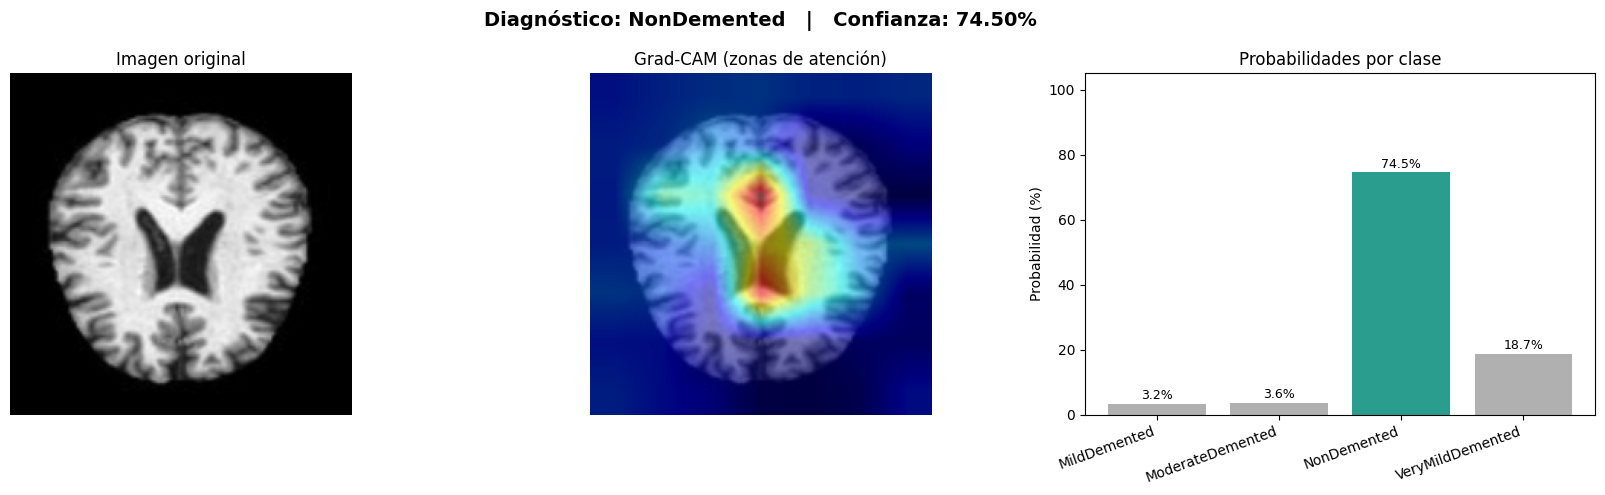

🧠 Grado de demencia diagnosticado: NonDemented  |  Confianza: 74.50%


In [ ]:
from google.colab import files

MODO_CARGA = "upload"     # "upload" (subir desde PC) | "ruta" (Drive/disco local)
RUTA_IMAGEN = "/content/drive/MyDrive/TallerWeb/mi_resonancia.jpg"

if MODO_CARGA == "upload":
    subidos = files.upload()
    for nombre_archivo in subidos:
        diagnosticar_con_gradcam(os.path.abspath(nombre_archivo))
else:
    diagnosticar_con_gradcam(RUTA_IMAGEN)